In [17]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [19]:
df = pd.read_csv("giovani_bahawalpur_temp.csv")

In [9]:
df.head(7)

,Title:,"Time Series, Area-Averaged of 2-meter air temperature monthly 0.5 x 0.625 (monthly)"
0,User Start Date:,2002-01-01T00:00:00Z
1,User End Date:,2026-12-31T23:59:59Z
2,User Bounding Box:,"29.3957,71.6833,29.3957,71.6833"
3,Data Bounding Box:,"29.375,71.5,29.375,71.5"
4,URL to Reproduce Results:,https://giovanni.gsfc.nasa.gov/giovanni/#servi...
5,Fill Value (mean_M2IMNXASM_5_12_4_T2M):,1000000000000000
6,time,mean_M2IMNXASM_5_12_4_T2M


In [20]:
print(df.columns.tolist())

['Title:', 'Time Series, Area-Averaged of 2-meter air temperature monthly 0.5 x 0.625 deg. [MERRA-2 (monthly)']


In [23]:
df = pd.read_csv("giovani_bahawalpur_temp.csv", skiprows=8)

In [24]:
df

,time,mean_M2TMNXSLV_5_12_4_T2M
0,2002-01-01 00:00:00,288.407074
1,2002-02-01 00:00:00,290.201538
2,2002-03-01 00:00:00,297.536682
3,2002-04-01 00:00:00,304.586182
4,2002-05-01 00:00:00,310.427307
...,...,...
292,2026-05-01 00:00:00,309.868500
293,2026-06-01 00:00:00,311.350098
294,2026-07-01 00:00:00,310.869171
295,2026-08-01 00:00:00,308.845276


In [25]:
# 1. Clean column names
df.columns = df.columns.str.strip()

# 2. Display dataset overview
print("===== DATASET OVERVIEW =====")
print("Total Rows and Columns:", df.shape)
print("\nColumn Names:", df.columns.tolist())

# 3. Display first 5 records
print("\n===== FIRST 5 RECORDS =====")
display(df.head())

# 4. Check data types
print("\n===== DATA TYPES =====")
print(df.dtypes)

# 5. Check missing values
print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

# 6. Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 7. Statistical summary
print("\n===== STATISTICAL SUMMARY =====")
display(df.describe())

# 8. Check dataset date range (if first column contains dates)
print("\n===== DATE RANGE =====")
dates = pd.to_datetime(df.iloc[:, 0], errors="coerce")
print("Start Date:", dates.min())
print("End Date:", dates.max())

===== DATASET OVERVIEW =====
Total Rows and Columns: (297, 2)

Column Names: ['time', 'mean_M2TMNXSLV_5_12_4_T2M']

===== FIRST 5 RECORDS =====


,time,mean_M2TMNXSLV_5_12_4_T2M
0,2002-01-01 00:00:00,288.407074
1,2002-02-01 00:00:00,290.201538
2,2002-03-01 00:00:00,297.536682
3,2002-04-01 00:00:00,304.586182
4,2002-05-01 00:00:00,310.427307



===== DATA TYPES =====
time                          object
mean_M2TMNXSLV_5_12_4_T2M    float64
dtype: object

===== MISSING VALUES =====
time                         0
mean_M2TMNXSLV_5_12_4_T2M    0
dtype: int64

Duplicate Records: 0

===== STATISTICAL SUMMARY =====


,mean_M2TMNXSLV_5_12_4_T2M
count,297.000000
mean,300.886774
std,8.481440
min,285.344452
25%,293.603790
50%,302.415833
75%,308.844238
max,312.926544



===== DATE RANGE =====
Start Date: 2002-01-01 00:00:00
End Date: 2026-09-01 00:00:00


In [26]:
# 1. Identify date and temperature columns
time_col = df.columns[0]
temp_col = df.columns[1]

# 2. Convert date column into datetime format
df['datetime'] = pd.to_datetime(df[time_col], errors='coerce')

# 3. Convert temperature column into numeric format
df[temp_col] = pd.to_numeric(df[temp_col], errors='coerce')

# 4. Remove missing observations
df = df.dropna(subset=['datetime', temp_col]).copy()

# 5. Extract year and month
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month

# 6. Convert Kelvin into Celsius
df['temp_c'] = df[temp_col] - 273.15

# 7. Display cleaned dataset
print("Cleaned Dataset:")
display(df.head(10))

# 8. Display temperature statistics
print("\nTemperature Statistics (°C):")
print("Average:", round(df['temp_c'].mean(), 2))
print("Maximum:", round(df['temp_c'].max(), 2))
print("Minimum:", round(df['temp_c'].min(), 2))

# 9. Display date range
print("\nDate Range:")
print(df['datetime'].min(), "to", df['datetime'].max())

Cleaned Dataset:


,time,mean_M2TMNXSLV_5_12_4_T2M,datetime,year,month,temp_c
0,2002-01-01 00:00:00,288.407074,2002-01-01,2002,1,15.257074
1,2002-02-01 00:00:00,290.201538,2002-02-01,2002,2,17.051538
2,2002-03-01 00:00:00,297.536682,2002-03-01,2002,3,24.386682
3,2002-04-01 00:00:00,304.586182,2002-04-01,2002,4,31.436182
4,2002-05-01 00:00:00,310.427307,2002-05-01,2002,5,37.277307
5,2002-06-01 00:00:00,312.926544,2002-06-01,2002,6,39.776544
6,2002-07-01 00:00:00,311.559235,2002-07-01,2002,7,38.409235
7,2002-08-01 00:00:00,310.356201,2002-08-01,2002,8,37.206201
8,2002-09-01 00:00:00,306.522125,2002-09-01,2002,9,33.372125
9,2002-10-01 00:00:00,302.082062,2002-10-01,2002,10,28.932062



Temperature Statistics (°C):
Average: 27.74
Maximum: 39.78
Minimum: 12.19

Date Range:
2002-01-01 00:00:00 to 2026-09-01 00:00:00


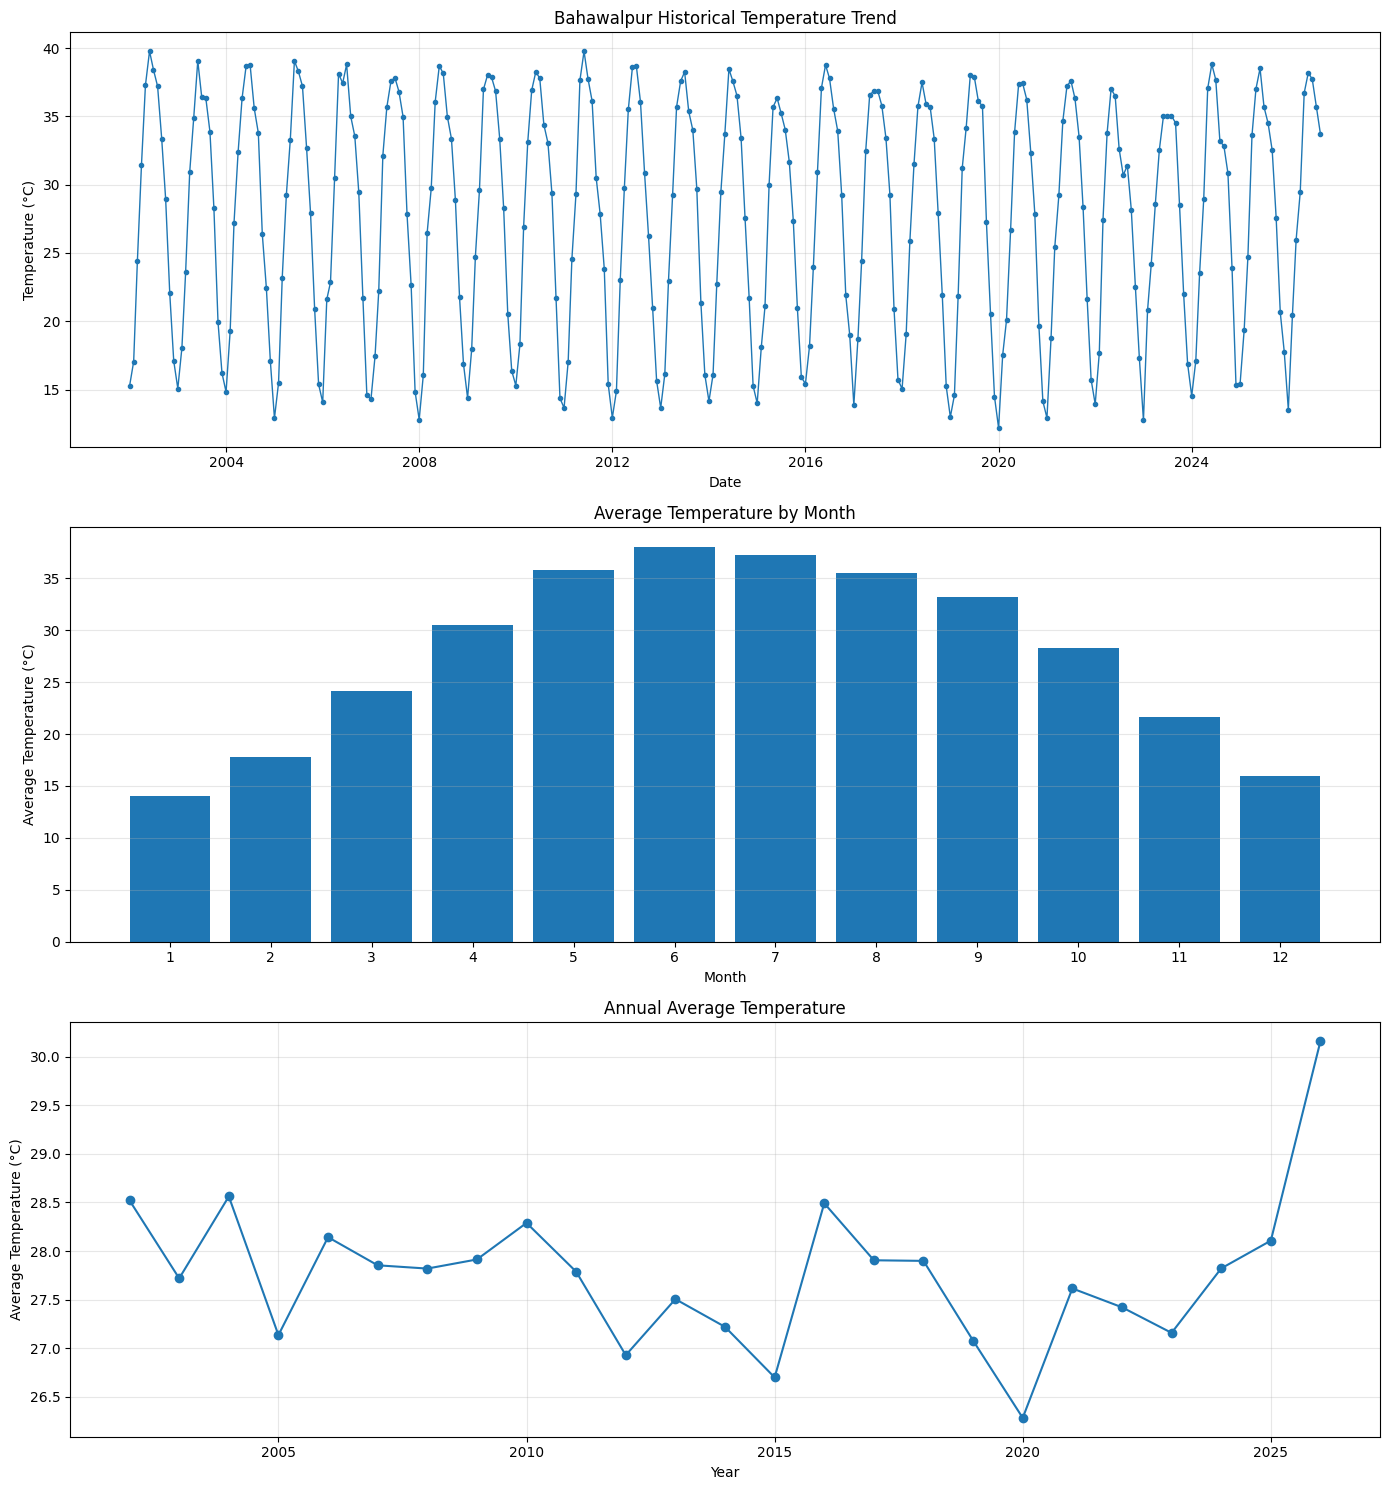

In [28]:
import matplotlib.pyplot as plt

# Make sure datetime is in the correct format
df['datetime'] = pd.to_datetime(df['datetime'])

# Create a figure with 3 visualizations
fig, axes = plt.subplots(3, 1, figsize=(14, 15))

# 1. Historical temperature trend
axes[0].plot(df['datetime'], df['temp_c'], marker='.', linewidth=1)
axes[0].set_title('Bahawalpur Historical Temperature Trend')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Temperature (°C)')
axes[0].grid(alpha=0.3)

# 2. Monthly average temperature
monthly_temp = df.groupby('month')['temp_c'].mean()

axes[1].bar(monthly_temp.index, monthly_temp.values)
axes[1].set_title('Average Temperature by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Temperature (°C)')
axes[1].set_xticks(range(1, 13))
axes[1].grid(axis='y', alpha=0.3)

# 3. Annual average temperature
yearly_temp = df.groupby('year')['temp_c'].mean()

axes[2].plot(yearly_temp.index, yearly_temp.values, marker='o')
axes[2].set_title('Annual Average Temperature')
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Average Temperature (°C)')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Average Temperature: 27.74 °C

===== TEMPERATURE TREND ANALYSIS =====
Slope: -0.0012 °C/year
Temperature change per decade: -0.012 °C
R-squared: 0.0
P-value: 0.98619
Statistical result: No statistically significant linear trend
Direction: Decreasing temperature


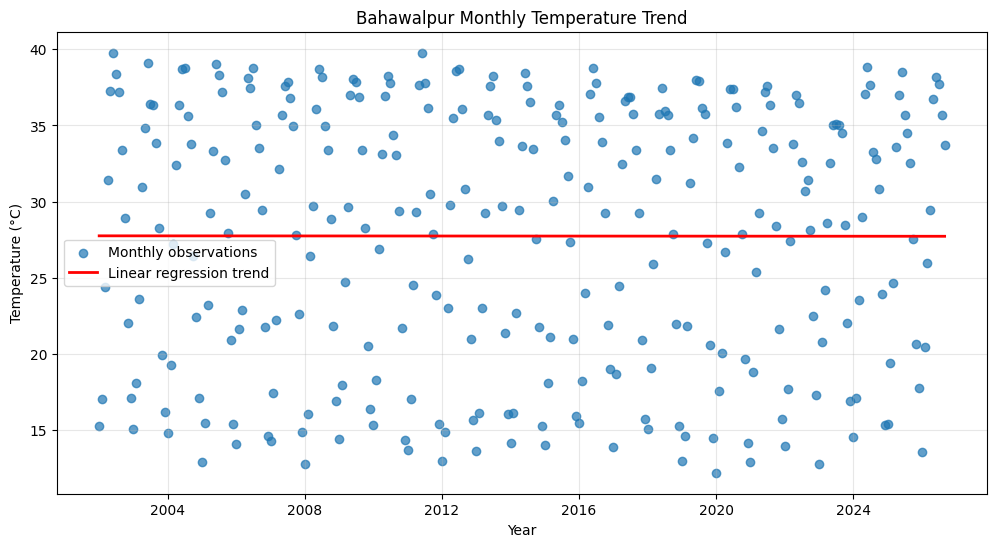

In [29]:
import numpy as np
from scipy.stats import linregress

# 1. Prepare monthly temperature data
df['datetime'] = pd.to_datetime(df['datetime'])

# Sort observations by date
df = df.sort_values('datetime').copy()

# 2. Calculate average temperature
average_temp = df['temp_c'].mean()
print("Average Temperature:", round(average_temp, 2), "°C")

# 3. Prepare regression variables
# Convert dates into elapsed years
df['years_elapsed'] = (
    df['datetime'] - df['datetime'].min()
).dt.total_seconds() / (365.2425 * 24 * 60 * 60)

# 4. Perform linear regression
result = linregress(
    df['years_elapsed'],
    df['temp_c']
)

# 5. Calculate temperature trend per decade
decadal_trend = result.slope * 10

# 6. Display results
print("\n===== TEMPERATURE TREND ANALYSIS =====")

print("Slope:", round(result.slope, 4), "°C/year")
print("Temperature change per decade:", round(decadal_trend, 3), "°C")
print("R-squared:", round(result.rvalue**2, 4))
print("P-value:", round(result.pvalue, 5))

if result.pvalue < 0.05:
    print("Statistical result: Significant linear trend")
else:
    print("Statistical result: No statistically significant linear trend")

if result.slope > 0:
    print("Direction: Increasing temperature")
elif result.slope < 0:
    print("Direction: Decreasing temperature")
else:
    print("Direction: No linear change")

# 7. Plot regression line
plt.figure(figsize=(12, 6))

plt.scatter(
    df['datetime'],
    df['temp_c'],
    label='Monthly observations',
    alpha=0.7
)

predicted_temp = (
    result.intercept +
    result.slope * df['years_elapsed']
)

plt.plot(
    df['datetime'],
    predicted_temp,
    color='red',
    linewidth=2,
    label='Linear regression trend'
)

plt.title('Bahawalpur Monthly Temperature Trend')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

===== ANNUAL MEAN CLIMATE TREND =====
Overall Rate: -0.287 °C / decade
p-value: 0.0970 (Not Significant)
R-squared: 0.1202

===== 12-MONTH WARMING RATES (°C / DECADE) =====
Month  Rate_per_decade  p_value  Significant
  Jan        -0.289345 0.285690        False
  Feb         0.524326 0.290860        False
  Mar         0.042438 0.937186        False
  Apr        -0.248538 0.612908        False
  May        -0.237553 0.570961        False
  Jun        -0.702168 0.017887         True
  Jul        -0.968783 0.011042         True
  Aug        -0.873842 0.020707         True
  Sep        -0.096916 0.776952        False
  Oct         0.165461 0.603626        False
  Nov         0.066338 0.835099        False
  Dec         0.107795 0.764512        False


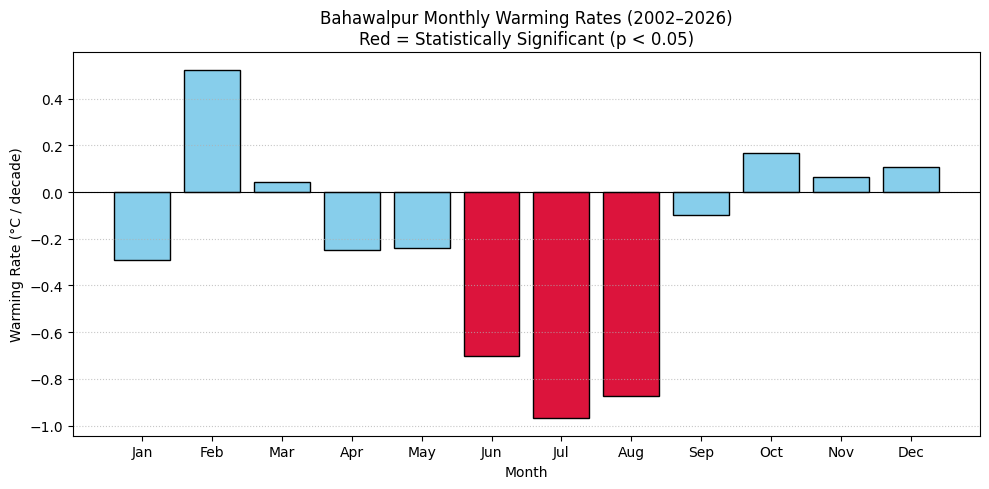

In [31]:
# ---------------------------------------------------------
# A. ANNUAL MEAN TREND (2002–2025 complete years)
# ---------------------------------------------------------
annual_df = df[df['year'] < 2026].groupby('year')['temp_c'].mean().reset_index()
ann_res = linregress(annual_df['year'], annual_df['temp_c'])

print("===== ANNUAL MEAN CLIMATE TREND =====")
print(f"Overall Rate: {ann_res.slope * 10:+.3f} °C / decade")
print(f"p-value: {ann_res.pvalue:.4f} ({'Statistically Significant' if ann_res.pvalue < 0.05 else 'Not Significant'})")
print(f"R-squared: {ann_res.rvalue**2:.4f}\n")

# ---------------------------------------------------------
# B. MONTH-BY-MONTH WARMING RATES (All 12 Months)
# ---------------------------------------------------------
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_trends = []

for m in range(1, 13):
    m_df = df[df['month'] == m]
    res = linregress(m_df['year'], m_df['temp_c'])
    monthly_trends.append({
        'Month': month_names[m-1],
        'Rate_per_decade': res.slope * 10,
        'p_value': res.pvalue,
        'Significant': res.pvalue < 0.05
    })

trends_df = pd.DataFrame(monthly_trends)
print("===== 12-MONTH WARMING RATES (°C / DECADE) =====")
print(trends_df.to_string(index=False))

# ---------------------------------------------------------
# C. PLOT THE 12-MONTH WARMING PROFILE
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
colors = ['crimson' if sig else 'skyblue' for sig in trends_df['Significant']]
plt.bar(trends_df['Month'], trends_df['Rate_per_decade'], color=colors, edgecolor='black')
plt.axhline(0, color='black', linewidth=0.8)
plt.title("Bahawalpur Monthly Warming Rates (2002–2026)\nRed = Statistically Significant (p < 0.05)", fontsize=12)
plt.xlabel("Month")
plt.ylabel("Warming Rate (°C / decade)")
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()